In [1]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import glob,os

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass


## Get MG5 Cross Sections

In [2]:
xsecFile = '../pp2Sd_xsections_13TeV.csv'
xsecDF = pd.read_csv(xsecFile).sort_values(by='mS')
# xsecDF[['mS',"sigma(21,21 -> 55) (pb)"]]

## Get NLO Xsecs (sina = 1)

In [3]:
xsecWG = pd.read_csv('../xsec_ggf_HiggsWG.csv',skiprows=1,delimiter=',',skipinitialspace=True).rename(columns={'mS (GeV)': 'mS', 
                                                                                                               'xsecPointLike (pb)' : 'xs13_PointLike', 
                                                                                                               'xsecQuarkLoop (pb)' : 'xs13_QuarkLoop'}).sort_values(by='mS')

## Compute k-factor

In [4]:
xsecAll = xsecDF.merge(xsecWG,on='mS',how='left',suffixes=('', '_NLO'))
xsecAll['kFactor13PL'] = xsecAll['xs13_PointLike']*xsecAll['sina']**2/xsecAll['sigma(21,21 -> 55) (pb)']
xsecAll['kFactor13'] = xsecAll['xs13_QuarkLoop']*xsecAll['sina']**2/xsecAll['sigma(21,21 -> 55) (pb)']
xsecAll[['mS','sigma(21,21 -> 55) (pb)','xs13_PointLike','xs13_QuarkLoop','kFactor13']]

,mS,"sigma(21,21 -> 55) (pb)",xs13_PointLike,xs13_QuarkLoop,kFactor13
0,250.0,0.182340,10.200,12.500,2.742130
1,300.0,0.141120,6.590,9.820,2.783447
2,350.0,0.143930,4.480,10.300,2.862503
3,400.0,0.133900,3.160,9.520,2.843913
4,450.0,0.095223,2.300,6.770,2.843851
5,500.0,0.063868,1.710,4.540,2.843364
6,600.0,0.027944,1.000,2.010,2.877183
7,700.0,0.012771,0.621,0.924,2.894057
8,800.0,0.006145,0.402,0.449,2.922844
9,900.0,0.003126,0.269,0.230,2.943058


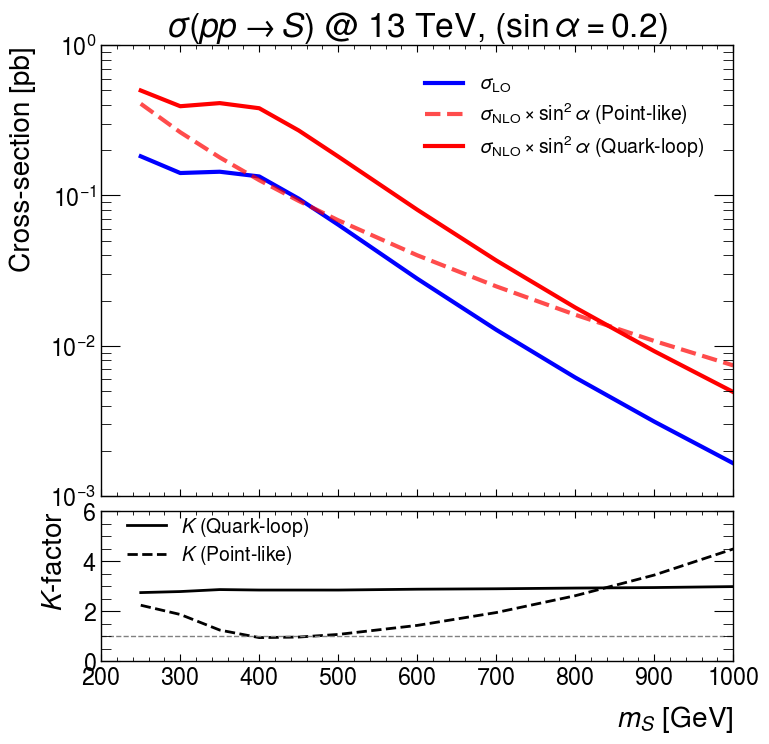

In [21]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8,8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05})
sina = xsecAll['sina'].iloc[0]

# Top panel: cross-sections
ax1.plot(xsecAll['mS'],xsecAll['sigma(21,21 -> 55) (pb)'],label=r'$\sigma_{\text{LO}}$',color='blue',linewidth=3)
ax1.plot(xsecAll['mS'],xsecAll['xs13_PointLike']*xsecAll['sina']**2,
         label=r'$\sigma_{\text{NLO}} \times \sin^2\alpha$ (Point-like)',
         color='red',linestyle='--',alpha=0.7,linewidth=3)
ax1.plot(xsecAll['mS'],xsecAll['xs13_QuarkLoop']*xsecAll['sina']**2,
         label=r'$\sigma_{\text{NLO}} \times \sin^2\alpha$ (Quark-loop)',
         color='red',linewidth=3)
ax1.set_yscale('log')
ax1.set_ylabel('Cross-section [pb]')
ax1.set_title(rf'$\sigma(p p \to S)$ @ 13 TeV, ($\sin\alpha={sina}$)')
ax1.legend()

# Bottom panel: k-factor
ax2.plot(xsecAll['mS'],xsecAll['kFactor13'],color='black',label=r'$K$ (Quark-loop)')
ax2.plot(xsecAll['mS'],xsecAll['kFactor13PL'],color='black',linestyle='--',label=r'$K$ (Point-like)')
ax2.legend(loc=(0.01,0.5))
ax2.axhline(1.0,color='gray',linestyle='--',linewidth=1)
ax2.set_xlabel(r'$m_S$ [GeV]')
ax2.set_ylabel(r'$K$-factor')
plt.savefig('./xsec_vs_mS.png',dpi=300, bbox_inches='tight')
plt.show()